# In-Game Summary Statistics

Explore **Stats Summary** and **Possession & Time** using pandas and Altair. Summary tables cover the full game, halves and quarters. Tackle charts compare **EG to the right of zero** and **Opposition to the left**. The possession dashboard covers ball-in-play time, territory, possession and action zones. The Events worksheet is not used for analysis.

**Tackle definitions:** `+` means **Dominant**, `-` means **Passive**, and `Miss` means **Missed**. **Made = Total - Missed**. **Neutral = Made - Dominant - Passive** is treated as the residual made-tackle category, rather than a separately observed source label. Whole-match donuts show **Dominant, Neutral, Passive, Missed**, normalized independently for each team, with completion rates in their centres. Total and quarterly bars show only **Made** and **Missed**. **Tackle percentage = Made / (Made + Missed)**; it is undefined when there are no attempts.

**Interpretation and source quality:** Full game, halves and quarters overlap and must not be added. Raw source values are unchanged; made and neutral rows are marked `is_derived=True`. Invalid or negative tackle categories raise an error. Other metrics retain unconfirmed source-label meanings, and possession-duration rounding differences remain visible. No match date or squad is inferred.

## 1. Load the summary tables

Run top to bottom with the project's `.venv` Python kernel. The local export is read by default. Set `REFRESH_FROM_DRIVE = True` for a read-only refresh using existing credentials. Optional `GAME_ID` applies only to the refreshed snapshot; neither the source nor the local export is overwritten.

In [1]:
import importlib
import json
import sys
from pathlib import Path
from typing import Any

import altair as alt
import pandas as pd
from IPython.display import Markdown, display

REFRESH_FROM_DRIVE = False
GAME_ID = None

project_root = next(
    (directory for directory in [Path.cwd(), *Path.cwd().parents]
     if (directory / 'pyproject.toml').exists()
     and (directory / 'python/in_game_stats.py').exists()),
    None,
 )
if project_root is None:
    raise FileNotFoundError('Open the notebook from the repository root or a subdirectory.')
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

data_path = project_root / 'reports/generated/in_game_stats/in_game_stats.json'
if REFRESH_FROM_DRIVE:
    import python.in_game_stats as in_game_stats
    importlib.reload(in_game_stats)
    stats = in_game_stats.parse_workbook(
        in_game_stats.InGameStatsSource().read_workbook(), game_id=GAME_ID
    )
else:
    if not data_path.exists():
        raise FileNotFoundError(
            'Export missing. Run python -m python.in_game_stats from the repository root, '
            'or set REFRESH_FROM_DRIVE = True.'
        )
    stats = json.loads(data_path.read_text(encoding='utf-8'))

summary = pd.DataFrame(stats['summary'])
possession = pd.DataFrame(stats['possession'])
teams = sorted(summary.loc[~summary['is_total'], 'team'].dropna().unique().tolist())
metrics = sorted(summary['metric'].dropna().unique().tolist())
team_scale = alt.Scale(
    domain=teams,
    range=['#202946' if team == 'EG' else '#7d96e8' for team in teams],
)

def present(chart: Any) -> None:
    """Validate and display a chart with the club's typography and colours."""
    styled = chart.configure(
        font='PT Sans Narrow', background='#f2f1f4',
        # axis={'labelFontSize': 12, 'titleFontSize': 13},
        # header={'labelFontSize': 14, 'titleFontSize': 15},
        # title={'fontSize': 17, 'anchor': 'start', 'color': '#202946'},
        view={'stroke': None},
    )
    styled.to_dict(validate=True)
    display(styled)

display(pd.DataFrame([
    {'table': name, 'rows': len(frame), 'columns': len(frame.columns)}
    for name, frame in [('summary', summary), ('possession', possession)]
]))
print('Source:', stats['source']['name'], '| Fetched:', stats.get('fetched_at', 'live snapshot'))
for warning in stats.get('warnings', []):
    print('Source warning:', warning)

,table,rows,columns
0,summary,306,12
1,possession,42,8


Source: Stats.xlsx | Fetched: 2026-10-21T21:50:45.670581+00:00
Source warning: No game_id supplied; match date and squad are not inferred.


In [2]:
def generic_summary_tables(
    summary_source: pd.DataFrame, possession_source: pd.DataFrame,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Use generic display labels while leaving the source tables unchanged."""
    source_teams = summary_source.loc[~summary_source['is_total'], 'team'].dropna().unique().tolist()
    opposition_names = [team for team in source_teams if team != 'EG']
    if 'EG' not in source_teams or len(opposition_names) != 1:
        raise ValueError('Generic labels require EG and exactly one opposition team.')
    source_opposition = opposition_names[0]
    summary_view = summary_source.copy(deep=True)
    possession_view = possession_source.copy(deep=True)
    summary_view['team'] = summary_view['team'].replace({source_opposition: 'Opposition'})
    header_mapping = {
        f'{source_opposition}{suffix}': f'Opposition{suffix}'
        for suffix in ['', ' 1st', ' 2nd', ' Q1', ' Q2', ' Q3', ' Q4']
    }
    summary_view['source_header'] = summary_view['source_header'].replace(header_mapping)
    possession_view['measure'] = possession_view['measure'].replace({
        f'EG in opposition half ({source_opposition})': 'EG in opposition half (Opposition)',
        f"{source_opposition} in EG's half": "Opposition in EG's half",
        f'{source_opposition} in own half': 'Opposition in own half',
    })
    return summary_view, possession_view

raw_summary = pd.DataFrame(stats['summary'])
raw_possession = pd.DataFrame(stats['possession'])
summary, possession = generic_summary_tables(raw_summary, raw_possession)
teams = sorted(summary.loc[~summary['is_total'], 'team'].dropna().unique().tolist())
team_scale = alt.Scale(domain=teams, range=['#202946' if team == 'EG' else '#7d96e8' for team in teams])

In [3]:
from python.chart_helpers import alt_theme

alt.theme.register('my_custom_theme', enable=True)(alt_theme)

<function python.chart_helpers.alt_theme()>

## 2. Inspect and filter

Edit `SELECTED_TEAMS` and `SELECTED_METRICS` for Stats Summary, and `SELECTED_MEASURES` for Possession & Time. Then rerun this cell and the cells below. Display labels use **EG** and **Opposition** throughout the analysis and exports; the original workbook labels remain available in `raw_summary`, `raw_possession` and the unmodified source snapshot.

Period columns are ordered `Total`, `H1`, `H2`, `Q1`, `Q2`, `Q3`, `Q4`. Source rows are retained for traceability. Null `game_id` values are expected until the match is linked, and null summary outcomes identify parent totals.

In [4]:
for table_name, frame in [('summary', summary), ('possession', possession)]:
    display(Markdown(f'### {table_name}'))
    display(pd.DataFrame({'dtype': frame.dtypes.astype(str), 'nulls': frame.isna().sum()}))
    display(frame.head(3))

SELECTED_TEAMS = teams.copy()
SELECTED_METRICS = metrics.copy()
SELECTED_MEASURES = possession['measure'].drop_duplicates().tolist()

period_labels = {
    'full_game': 'Total',
    'first_half': 'H1', 'second_half': 'H2',
    'quarter_1': 'Q1', 'quarter_2': 'Q2', 'quarter_3': 'Q3', 'quarter_4': 'Q4',
}
period_order = list(period_labels.values())
filtered_summary = summary.loc[
    ~summary['is_total']
    & summary['team'].isin(SELECTED_TEAMS)
    & summary['metric'].isin(SELECTED_METRICS)
].copy()
filtered_summary['statistic'] = filtered_summary['outcome'].fillna('Total')
filtered_summary['is_derived'] = False
tackle_mask = filtered_summary['metric'].eq('Tackles')
tackle_labels = {'+': 'Dominant', '-': 'Passive', 'Miss': 'Missed'}
labelled_tackles = tackle_mask & filtered_summary['outcome'].isin(tackle_labels)
filtered_summary.loc[labelled_tackles, 'statistic'] = (
    filtered_summary.loc[labelled_tackles, 'outcome'].map(tackle_labels)
 )
tackle_totals = filtered_summary.loc[tackle_mask & filtered_summary['outcome'].isna()]
tackle_misses = filtered_summary.loc[
    tackle_mask & filtered_summary['outcome'].eq('Miss'),
    ['team', 'period', 'count', 'source_row'],
]
if not tackle_totals.empty:
    made_tackles = tackle_totals.merge(
        tackle_misses.rename(columns={'count': 'missed_count', 'source_row': 'miss_source_row'}),
        on=['team', 'period'], how='left', validate='one_to_one',
    )
    if made_tackles['missed_count'].isna().any():
        raise ValueError('Cannot derive tackles made: a missed-tackle summary is missing.')
    made_tackles['count'] = made_tackles['count'] - made_tackles['missed_count']
    if made_tackles['count'].lt(0).any():
        raise ValueError('Missed tackles exceed the tackle total.')
    made_tackles['statistic'] = 'Made'
    made_tackles['is_derived'] = True
    filtered_summary = pd.concat([filtered_summary, made_tackles], ignore_index=True)
filtered_summary['period_label'] = filtered_summary['period'].map(period_labels)
filtered_possession = possession.loc[possession['measure'].isin(SELECTED_MEASURES)].copy()
filtered_possession['period_label'] = filtered_possession['period'].map({
    'Full game': 'Total', 'First half': 'H1', 'Second half': 'H2',
    'Start-20': 'Q1', '20-HT': 'Q2', '2nd-60': 'Q3', '60-End': 'Q4',
})
filtered_possession['minutes'] = filtered_possession['duration_seconds'] / 60
assert filtered_summary['period_label'].notna().all(), 'Unrecognized summary period.'
assert filtered_possession['period_label'].notna().all(), 'Unrecognized possession period.'
print('Available teams:', teams)
print('Available metrics:', metrics)
print('Available possession/time measures:', possession['measure'].drop_duplicates().tolist())

### summary

,dtype,nulls
source_file_id,object,0
worksheet,object,0
source_row,int64,0
game_id,object,306
section,object,0
metric,object,0
outcome,object,102
team,object,54
period,object,0
is_total,bool,0


,source_file_id,worksheet,source_row,game_id,section,metric,outcome,team,period,is_total,source_header,count
0,1anXzVX7sC1Z5fFJIKLttb2vqsKaruSLY,Stats Summary,3,None,Full Game,Scrum,None,EG,full_game,False,EG,10.0
1,1anXzVX7sC1Z5fFJIKLttb2vqsKaruSLY,Stats Summary,3,None,Full Game,Scrum,None,Opposition,full_game,False,Opposition,3.0
2,1anXzVX7sC1Z5fFJIKLttb2vqsKaruSLY,Stats Summary,3,None,Full Game,Scrum,None,None,all_periods,True,Total,13.0


### possession

,dtype,nulls
source_file_id,object,0
worksheet,object,0
source_row,int64,0
game_id,object,42
measure,object,0
period,object,0
duration_text,object,0
duration_seconds,int64,0


,source_file_id,worksheet,source_row,game_id,measure,period,duration_text,duration_seconds
0,1anXzVX7sC1Z5fFJIKLttb2vqsKaruSLY,Possession & Time,4,None,EG in opposition half (Opposition),Full game,06:24,384
1,1anXzVX7sC1Z5fFJIKLttb2vqsKaruSLY,Possession & Time,4,None,EG in opposition half (Opposition),First half,03:59,239
2,1anXzVX7sC1Z5fFJIKLttb2vqsKaruSLY,Possession & Time,4,None,EG in opposition half (Opposition),Second half,02:25,145


Available teams: ['EG', 'Opposition']
Available metrics: ['Lineout', 'Red Zone Entry', 'Red Zone Entry Def', 'Ruck Speed', 'Scrum', 'Tackles']
Available possession/time measures: ['EG in opposition half (Opposition)', 'EG in own half', "Opposition in EG's half", 'Opposition in own half', 'Ball out of play', 'Total ball in play']


In [5]:
def build_tackle_stats(frame: pd.DataFrame) -> pd.DataFrame:
    """Derive neutral tackles and completion rate from source tackle summaries."""
    tackle_rows = frame.loc[frame['metric'].eq('Tackles')]
    columns = ['Total', 'Made', 'Dominant', 'Passive', 'Missed']
    wide = tackle_rows.pivot(index=['team', 'period_label'], columns='statistic', values='count').reindex(columns=columns)
    if wide.empty:
        return wide.reindex(columns=[*columns, 'Neutral', 'tackle_percentage'])
    if wide[columns].isna().any().any() or wide[columns].lt(0).any().any():
        raise ValueError('Tackle summaries require complete, non-negative source counts.')
    if not wide['Made'].eq(wide['Total'] - wide['Missed']).all():
        raise ValueError('Tackles made must equal total tackles minus missed tackles.')
    wide['Neutral'] = wide['Made'] - wide['Dominant'] - wide['Passive']
    if wide['Neutral'].lt(0).any():
        raise ValueError('Dominant and passive tackles exceed tackles made; neutral cannot be negative.')
    attempts = wide['Made'] + wide['Missed']
    wide['tackle_percentage'] = wide['Made'].div(attempts.where(attempts.ne(0)))
    return wide

filtered_summary = filtered_summary.loc[~(
    filtered_summary['metric'].eq('Tackles') & filtered_summary['statistic'].eq('Neutral') & filtered_summary['is_derived']
)].copy()
tackle_stats = build_tackle_stats(filtered_summary)
if not tackle_stats.empty:
    neutral_rows = filtered_summary.loc[
        filtered_summary['metric'].eq('Tackles') & filtered_summary['statistic'].eq('Made')
    ].copy()
    neutral_rows['count'] = [
        tackle_stats.loc[(team, period), 'Neutral']
        for team, period in zip(neutral_rows['team'], neutral_rows['period_label'])
    ]
    neutral_rows['statistic'] = 'Neutral'
    neutral_rows['is_derived'] = True
    filtered_summary = pd.concat([filtered_summary, neutral_rows], ignore_index=True)
    display(tackle_stats[['Made', 'Missed', 'Neutral', 'tackle_percentage']])

statistic                 Made  Missed  Neutral  tackle_percentage
team       period_label                                           
EG         H1             58.0    12.0     26.0           0.828571
           H2             57.0     9.0     32.0           0.863636
           Q1             25.0     1.0      8.0           0.961538
           Q2             33.0    11.0     18.0           0.750000
           Q3             15.0     2.0      6.0           0.882353
           Q4             42.0     7.0     26.0           0.857143
           Total         115.0    21.0     58.0           0.845588
Opposition H1             25.0     9.0     14.0           0.735294
           H2             13.0     8.0      8.0           0.619048
           Q1             11.0     5.0      4.0           0.687500
           Q2             14.0     4.0     10.0           0.777778
           Q3              7.0     6.0      4.0           0.538462
           Q4              6.0     2.0      4.0           0.750000
           Total          38.0    17.0     22.0           0.690909

## 3. Summary Tables and Tackle Statistics

Exact metric values are tabulated for the full game, halves and quarters. The Tackles section then shows **Opposition** and **EG** normalized whole-match donuts, followed by one combined tackle bar chart.

Each donut retains **Dominant, Neutral, Passive, Missed**, with opacity **1.0 / 0.65 / 0.35** for the made-tackle categories. The ring is normalized independently for each team, with the **tackle completion rate** in its centre. Counts appear within sufficiently large slices. The donuts replace the overall made/missed/completion table.

The **single tackle bar chart** shows **Total** above **Q1-Q4**, with independent x axes. Both panels show only **Made** and **Missed**: made tackles are solid **EG blue** or **Opposition red**, while missed tackles are **white with a black border**. Opposition is negative/left; EG is positive/right. Counts are centred within segments where space permits, and Made/Miss annotations appear above Total only. Zero dividers, positive-magnitude ticks and row padding match possession/territory.

Neutral tackles are derived as **total - missed - dominant - passive**. Consistency checks include neutral tackles and compare overlapping periods without summing them. Only Stats Summary is used, never Events.

The single bar-chart Vega-Lite export is `data/charts/in_game_tackles.json`, with preview `reports/generated/in_game_stats/notebook/in_game_tackles.html`. Underlying overall made/missed/completion values remain available as `tackle_summary.csv` in the preview directory.

In [6]:
for metric in SELECTED_METRICS:
    metric_data = filtered_summary.loc[filtered_summary['metric'].eq(metric)]
    if metric_data.empty:
        continue
    display(Markdown(f'### {metric}'))
    metric_table = metric_data.pivot(
        index=['team', 'statistic'], columns='period_label', values='count',
    ).reindex(columns=period_order)
    display(metric_table)

### Lineout

period_label          Total   H1   H2   Q1   Q2   Q3   Q4
team       statistic                                     
EG         +            7.0  3.0  4.0  1.0  2.0  2.0  2.0
           -            4.0  1.0  3.0  0.0  1.0  1.0  2.0
           Total       11.0  4.0  7.0  1.0  3.0  3.0  4.0
Opposition +            4.0  1.0  3.0  1.0  0.0  2.0  1.0
           -            6.0  3.0  3.0  2.0  1.0  2.0  1.0
           Total       10.0  4.0  6.0  3.0  1.0  4.0  2.0

### Red Zone Entry

period_label          Total   H1   H2   Q1   Q2   Q3   Q4
team       statistic                                     
EG         +            9.0  5.0  4.0  3.0  2.0  2.0  2.0
           -            0.0  0.0  0.0  0.0  0.0  0.0  0.0
           Total        9.0  5.0  4.0  3.0  2.0  2.0  2.0
Opposition +            5.0  3.0  2.0  0.0  3.0  1.0  1.0
           -            6.0  1.0  5.0  0.0  1.0  2.0  3.0
           Total       11.0  4.0  7.0  0.0  4.0  3.0  4.0

### Red Zone Entry Def

period_label          Total   H1   H2   Q1   Q2   Q3   Q4
team       statistic                                     
EG         +            1.0  1.0  0.0  1.0  0.0  0.0  0.0
           Total        1.0  1.0  0.0  1.0  0.0  0.0  0.0
Opposition +            0.0  0.0  0.0  0.0  0.0  0.0  0.0
           Total        0.0  0.0  0.0  0.0  0.0  0.0  0.0

... (2 outputs left out)

### Scrum

period_label          Total   H1   H2   Q1   Q2   Q3   Q4
team       statistic                                     
EG         +           10.0  6.0  4.0  4.0  2.0  2.0  2.0
           -            0.0  0.0  0.0  0.0  0.0  0.0  0.0
           Total       10.0  6.0  4.0  4.0  2.0  2.0  2.0
Opposition +            1.0  0.0  1.0  0.0  0.0  1.0  0.0
           -            2.0  1.0  1.0  0.0  1.0  0.0  1.0
           Total        3.0  1.0  2.0  0.0  1.0  1.0  1.0

### Tackles

period_label          Total    H1    H2    Q1    Q2    Q3    Q4
team       statistic                                           
EG         Dominant    26.0  20.0   6.0  15.0   5.0   3.0   3.0
           Made       115.0  58.0  57.0  25.0  33.0  15.0  42.0
           Missed      21.0  12.0   9.0   1.0  11.0   2.0   7.0
           Neutral     58.0  26.0  32.0   8.0  18.0   6.0  26.0
           Passive     31.0  12.0  19.0   2.0  10.0   6.0  13.0
           Total      136.0  70.0  66.0  26.0  44.0  17.0  49.0
Opposition Dominant     5.0   3.0   2.0   2.0   1.0   1.0   1.0
           Made        38.0  25.0  13.0  11.0  14.0   7.0   6.0
           Missed      17.0   9.0   8.0   5.0   4.0   6.0   2.0
           Neutral     22.0  14.0   8.0   4.0  10.0   4.0   4.0
           Passive     11.0   8.0   3.0   5.0   3.0   2.0   1.0
           Total       55.0  34.0  21.0  16.0  18.0  13.0   8.0

In [7]:
import re

tackle_colours = dict(re.findall(
    r'(--[a-z-]+)\s*:\s*(#[0-9a-fA-F]{6})\s*;',
    (project_root / 'css/variables.css').read_text(encoding='utf-8'),
))
tackle_order = ['Dominant', 'Neutral', 'Passive', 'Missed']
tackle_opacities = {'Dominant': 1.0, 'Neutral': 0.65, 'Passive': 0.35, 'Missed': 1.0}
tackle_team_colours = {'EG': tackle_colours['--primary-color'], 'Opposition': tackle_colours['--red-color']}
tackle_segments = tackle_stats.reset_index().melt(
    id_vars=['team', 'period_label'], value_vars=tackle_order,
    var_name='tackle_type', value_name='tackles',
)
tackle_segments['stack_order'] = tackle_segments['tackle_type'].map({name: index for index, name in enumerate(tackle_order)})
tackle_segments['tackle_opacity'] = tackle_segments['tackle_type'].map(tackle_opacities)
tackle_segments['segment_colour'] = tackle_segments['team'].map(tackle_team_colours)
missed_mask = tackle_segments['tackle_type'].eq('Missed')
tackle_segments.loc[missed_mask, 'segment_colour'] = '#ffffff'
tackle_segments = tackle_segments.sort_values(['period_label', 'team', 'stack_order'])
tackle_segments['stack_end'] = tackle_segments.groupby(['period_label', 'team'])['tackles'].cumsum()
tackle_segments['stack_start'] = tackle_segments['stack_end'] - tackle_segments['tackles']
tackle_segments = tackle_segments.merge(
    tackle_stats.reset_index()[['team', 'period_label', 'Total', 'Made', 'Missed', 'tackle_percentage']],
    on=['team', 'period_label'], how='left', validate='many_to_one',
)
tackle_segments['direction'] = tackle_segments['team'].map({'EG': 1, 'Opposition': -1})
tackle_segments['signed_start'] = tackle_segments['stack_start'] * tackle_segments['direction']
tackle_segments['signed_end'] = tackle_segments['stack_end'] * tackle_segments['direction']
tackle_segments['midpoint'] = (tackle_segments['signed_start'] + tackle_segments['signed_end']) / 2

def tackle_donut(team: str) -> Any:
    """Normalize the detailed whole-match tackle breakdown for one team."""
    chart_data = tackle_segments.loc[tackle_segments['team'].eq(team) & tackle_segments['period_label'].eq('Total')].copy()
    total = float(tackle_stats.loc[(team, 'Total'), 'Total'])
    chart_data['share'] = chart_data['tackles'] / total if total else 0.0
    completion = tackle_stats.loc[(team, 'Total'), 'tackle_percentage']
    base = alt.Chart(chart_data).encode(theta=alt.Theta('share:Q', stack=True), order=alt.Order('stack_order:Q'))
    arcs = base.mark_arc(
        innerRadius=39, outerRadius=58,
        stroke=alt.ExprRef(expr="datum.tackle_type === 'Missed' ? '#000000' : datum.segment_colour"),
        strokeWidth=alt.ExprRef(expr="datum.tackle_type === 'Missed' ? 0.6 : 1"),
        strokeDash=alt.ExprRef(expr="datum.tackle_type === 'Missed' ? [3, 2] : [1, 0]"),
    ).encode(
        color=alt.Color('segment_colour:N', scale=None, legend=None),
        fillOpacity=alt.FillOpacity('tackle_opacity:Q', scale=None, legend=None),
        tooltip=['team:N', 'tackle_type:N', alt.Tooltip('tackles:Q', format='.0f'), alt.Tooltip('share:Q', title='Share of attempts', format='.1%')],
    )
    counts = base.transform_filter(alt.datum.share >= 0.07).mark_text(radius=49, font='PT Sans Narrow', fontSize=11, fontWeight='bold').encode(
        text=alt.Text('tackles:Q', format='.0f'),
        color=alt.condition("datum.tackle_type === 'Passive' || datum.tackle_type === 'Missed'", alt.value('#111111'), alt.value('white')),
    )
    outcomes = base.transform_calculate(
        outcome_label="datum.tackle_type === 'Dominant' ? '+' : datum.tackle_type === 'Passive' ? '-' : datum.tackle_type === 'Missed' ? 'Missed' : ''",
    ).mark_text(radius=76, font='PT Sans Narrow', fontSize=14, fontWeight='bold', color='#111111').encode(text='outcome_label:N')
    centre = alt.Chart(pd.DataFrame({'completion': [f'{completion:.0%}' if pd.notna(completion) else '--']})).mark_text(
        font='PT Sans Narrow', fontSize=28, fontWeight='bold', color=tackle_team_colours[team],
    ).encode(text='completion:N')
    return (arcs + counts + outcomes + centre).properties(width=134, height=124)

def tackle_panel(periods: list[str]) -> Any:
    """Show made and missed tackles for both Total and quarter panels."""
    chart_data = tackle_segments.loc[tackle_segments['period_label'].isin(periods) & tackle_segments['tackle_type'].isin(['Dominant', 'Missed'])].copy()
    chart_data['tackle_type'] = chart_data['tackle_type'].replace({'Dominant': 'Made'})
    chart_data['tackles'] = chart_data['Made'].where(chart_data['tackle_type'].eq('Made'), chart_data['Missed'])
    chart_data['tackle_opacity'] = 1.0
    chart_data['stack_order'] = chart_data['tackle_type'].map({'Made': 0, 'Missed': 1})
    chart_data['stack_start'] = chart_data['Made'].where(chart_data['tackle_type'].eq('Missed'), 0)
    chart_data['stack_end'] = chart_data['stack_start'] + chart_data['tackles']
    chart_data['signed_start'] = chart_data['stack_start'] * chart_data['direction']
    chart_data['signed_end'] = chart_data['stack_end'] * chart_data['direction']
    chart_data['midpoint'] = (chart_data['signed_start'] + chart_data['signed_end']) / 2
    extent = max(1.0, float(chart_data['Total'].max())) * 1.1
    y_encoding = alt.Y('period_label:N', sort=periods, title=None, scale=alt.Scale(paddingInner=0.2, paddingOuter=0.1), axis=alt.Axis(labelFontSize=18, labelFontWeight='bold', labelPadding=12, tickSize=0, domain=False))
    outer_end = 'datum.tackles > 0 && datum.stack_end === datum.Total'
    bars = alt.Chart(chart_data).mark_rect(
        stroke=alt.ExprRef(expr="datum.tackle_type === 'Missed' ? '#000000' : datum.segment_colour"), strokeWidth=1,
        cornerRadiusTopLeft=alt.ExprRef(expr=f'datum.direction < 0 && {outer_end} ? 5 : 0'),
        cornerRadiusBottomLeft=alt.ExprRef(expr=f'datum.direction < 0 && {outer_end} ? 5 : 0'),
        cornerRadiusTopRight=alt.ExprRef(expr=f'datum.direction > 0 && {outer_end} ? 5 : 0'),
        cornerRadiusBottomRight=alt.ExprRef(expr=f'datum.direction > 0 && {outer_end} ? 5 : 0'),
    ).encode(
        y=y_encoding,
        x=alt.X('signed_end:Q', title='Tackle attempts', scale=alt.Scale(domain=[-extent, extent], nice=False), axis=alt.Axis(labelExpr="format(abs(datum.value), '.0f')", tickMinStep=1)),
        x2='signed_start:Q', color=alt.Color('segment_colour:N', scale=None, legend=None),
        fillOpacity=alt.FillOpacity('tackle_opacity:Q', scale=None, legend=None), order='stack_order:Q',
        tooltip=['team:N', 'period_label:N', 'tackle_type:N', alt.Tooltip('tackles:Q', format='.0f'), alt.Tooltip('tackle_percentage:Q', title='Tackle percentage', format='.1%')],
    )
    zero_backing = alt.Chart().mark_rule(color='white', strokeWidth=6).encode(x=alt.datum(0))
    baseline = alt.Chart().mark_rule(color='#111111', strokeWidth=3).encode(x=alt.datum(0))
    counts = alt.Chart(chart_data).transform_filter(alt.datum.tackles > 0).mark_text(
        baseline='middle', font='PT Sans Narrow', fontSize=16, fontWeight='bold',
    ).encode(
        y=y_encoding, x=alt.X('midpoint:Q', title='Tackle attempts', axis=alt.Axis(labelExpr="format(abs(datum.value), '.0f')")),
        text=alt.Text('tackles:Q', format='.0f'),
        color=alt.condition(alt.datum.tackle_type == 'Missed', alt.value('#111111'), alt.value('white')),
    )
    chart = bars + zero_backing + baseline + counts
    if periods == ['Total']:
        outcomes = alt.Chart(chart_data).transform_filter(alt.datum.tackles > 0).transform_calculate(
            outcome_label="datum.tackle_type === 'Made' ? 'Made' : 'Missed'",
        ).mark_text(baseline='bottom', font='PT Sans Narrow', fontSize=16, fontWeight='bold').encode(
            x=alt.X('midpoint:Q', title='Tackle attempts', axis=alt.Axis(labelExpr="format(abs(datum.value), '.0f')")),
            y=alt.value(-8), text='outcome_label:N',
            color=alt.condition(alt.datum.tackle_type == 'Missed', alt.value('#111111'), alt.Color('segment_colour:N', scale=None, legend=None)),
        )
        chart = chart + outcomes
    return chart.properties(width=680, height=64 if periods == ['Total'] else 192)

tackle_combined_chart = None
tackle_donut_charts = {}
if not tackle_stats.empty:
    tackle_overall = tackle_stats.xs('Total', level='period_label')[['Made', 'Missed', 'tackle_percentage']].rename(
        columns={'Made': 'Tackles made', 'Missed': 'Tackles missed', 'tackle_percentage': 'Tackle percentage'}
    )
    tackle_donut_charts = {team: tackle_donut(team) for team in ['Opposition', 'EG'] if team in teams}
    display(Markdown('### Tackles'))
    present(alt.hconcat(*[chart.properties(title=team) for team, chart in tackle_donut_charts.items()], spacing=24))
    tackle_combined_chart = alt.vconcat(tackle_panel(['Total']), tackle_panel(['Q1', 'Q2', 'Q3', 'Q4']), spacing=28).resolve_scale(x='independent', y='independent', color='shared').properties(title='Tackles')
    present(tackle_combined_chart)
    tackle_export_directory = project_root / 'data/charts'
    tackle_preview_directory = project_root / 'reports/generated/in_game_stats/notebook'
    tackle_export_directory.mkdir(parents=True, exist_ok=True)
    tackle_preview_directory.mkdir(parents=True, exist_ok=True)
    tackle_combined_chart.save(str(tackle_export_directory / 'in_game_tackles.json'))
    tackle_combined_chart.save(str(tackle_preview_directory / 'in_game_tackles.html'), inline=True)
    tackle_overall.to_csv(tackle_preview_directory / 'tackle_summary.csv')

### Tackles

alt.HConcatChart(...)

alt.VConcatChart(...)

In [8]:
summary_checks = filtered_summary.pivot(
    index=['metric', 'team', 'statistic'], columns='period_label', values='count',
).reindex(columns=period_order)
summary_checks['halves_sum'] = summary_checks[['H1', 'H2']].sum(axis=1, min_count=2)
summary_checks['quarters_sum'] = summary_checks[['Q1', 'Q2', 'Q3', 'Q4']].sum(axis=1, min_count=4)
summary_checks['halves_difference'] = summary_checks['halves_sum'] - summary_checks['Total']
summary_checks['quarters_difference'] = summary_checks['quarters_sum'] - summary_checks['Total']
summary_differences = summary_checks.loc[
    summary_checks[['halves_difference', 'quarters_difference']].ne(0).any(axis=1)
]
print('Summary rows with missing periods or differing totals:', len(summary_differences))
display(summary_differences)

Summary rows with missing periods or differing totals: 0


,,period_label,Total,H1,H2,Q1,Q2,Q3,Q4,halves_sum,quarters_sum,halves_difference,quarters_difference
metric,team,statistic,,,,,,,,,,,


In [9]:
if not tackle_stats.empty:
    tackle_checks = tackle_stats[['Total', 'Made', 'Dominant', 'Neutral', 'Passive', 'Missed']].copy()
    tackle_checks['category_difference'] = (
        tackle_checks['Total'] - tackle_checks[['Dominant', 'Neutral', 'Passive', 'Missed']].sum(axis=1)
    )
    tackle_checks['made_difference'] = (
        tackle_checks['Made'] - tackle_checks[['Dominant', 'Neutral', 'Passive']].sum(axis=1)
    )
    tackle_discrepancies = tackle_checks.loc[
        tackle_checks[['category_difference', 'made_difference']].ne(0).any(axis=1)
    ]
    print('Tackle rows with inconsistent category totals:', len(tackle_discrepancies))
    display(tackle_discrepancies)

Tackle rows with inconsistent category totals: 0


,statistic,Total,Made,Dominant,Neutral,Passive,Missed,category_difference,made_difference
team,period_label,,,,,,,,


## 4. Possession, Territory and Action Zones

Reported whole-game **ball-in-play time** appears first. Each chart has a visually separate **Total** panel above **Q1-Q4**. Time charts use independent x axes for the total and quarters; normalized charts share proportion scales.

- **Territory:** ball in the EG half is negative; ball in the opposition half is positive, regardless of possession.
- **Possession:** opposition possession is negative; EG possession is positive, regardless of field position.
- **Action zones:** left to right: opposition possession in EG half (**red**), opposition possession in opposition half (**light red**), EG possession in EG half (**light blue**), EG possession in opposition half (**blue**).

Colour encodes the team in possession using `--primary-color` and `--red-color`. Opacity encodes territory relative to that team: **solid in the attacking half**, **light in its own half**. Hover tooltips show category, exact time and proportion. There are no click-highlighting or team-filter controls.

Separate **time** and **normalized** versions are displayed and saved. The website can switch files instead of using an embedded chart toggle. Vega-Lite JSON exports are written to `data/charts/in_game_{territory|possession|action_zones}_{time|normalized}.json`; matching standalone HTML previews are written to `reports/generated/in_game_stats/notebook/`.

Proportions use the four classified ball-in-play zones, not elapsed match time including stoppages. Rounding differences from reported ball-in-play duration remain visible. Total and quarters overlap and must not be added. The complete splits do not use the inspection-only `SELECTED_MEASURES` filter.

In [10]:
possession_periods = {'Full game': 'Total', 'Start-20': 'Q1', '20-HT': 'Q2', '2nd-60': 'Q3', '60-End': 'Q4'}
dashboard_periods = list(possession_periods.values())
opponents = [team for team in teams if team != 'EG']
if len(opponents) != 1:
    raise ValueError('Possession analysis requires EG and one opposition team.')
opposition_team = opponents[0]
zone_mapping = pd.DataFrame([
    (f'EG in opposition half ({opposition_team})', 'EG', 'Opposition half', 'EG', 0),
    ('EG in own half', 'EG', 'EG half', opposition_team, 1),
    (f"{opposition_team} in EG's half", opposition_team, 'EG half', opposition_team, 2),
    (f'{opposition_team} in own half', opposition_team, 'Opposition half', 'EG', 3),
], columns=['measure', 'team', 'half', 'territory_team', 'zone_order'])
period_source = possession.loc[possession['period'].isin(possession_periods)].copy()
period_source['period_label'] = period_source['period'].map(possession_periods)
action_zones = period_source.merge(zone_mapping, on='measure', how='inner', validate='many_to_one')
coverage = action_zones.groupby('period_label')['measure'].agg(['count', 'nunique'])
if not coverage.reindex(dashboard_periods).eq(4).all().all():
    raise ValueError('Each total/quarter requires all four action zones.')
classified_seconds = action_zones.groupby('period_label')['duration_seconds'].sum()
if classified_seconds.le(0).any() or action_zones['duration_seconds'].lt(0).any():
    raise ValueError('Invalid action-zone durations.')
action_zones['category'] = action_zones['measure']
possession_splits = action_zones.groupby(['period_label', 'team'], as_index=False)['duration_seconds'].sum()
possession_splits['category'] = possession_splits['team'] + ' possession'
possession_splits['zone_order'] = possession_splits['team'].map({'EG': 0, opposition_team: 1})
territory_splits = action_zones.groupby(['period_label', 'territory_team'], as_index=False)['duration_seconds'].sum().rename(columns={'territory_team': 'team'})
territory_splits['category'] = territory_splits['team'].map({'EG': 'Opposition half (EG territory)', opposition_team: 'EG half (opposition territory)'})
territory_splits['zone_order'] = territory_splits['team'].map({'EG': 0, opposition_team: 1})
for split_data in [action_zones, possession_splits, territory_splits]:
    split_data['classified_seconds'] = split_data['period_label'].map(classified_seconds)
    split_data['share'] = split_data['duration_seconds'] / split_data['classified_seconds']
    split_data['minutes'] = split_data['duration_seconds'] / 60
    split_data['duration'] = split_data['duration_seconds'].map(lambda seconds: f'{int(seconds) // 60:02d}:{int(seconds) % 60:02d}')
reported_ball_time = period_source.loc[period_source['measure'].eq('Total ball in play'), ['period_label', 'duration_text', 'duration_seconds']].set_index('period_label').reindex(dashboard_periods)
if reported_ball_time['duration_seconds'].isna().any():
    raise ValueError('Missing reported ball-in-play time for a total/quarter.')
reported_ball_time['classified_seconds'] = classified_seconds
reported_ball_time['rounding_difference_seconds'] = reported_ball_time['classified_seconds'] - reported_ball_time['duration_seconds']
display(Markdown(f"### Total ball in play: **{reported_ball_time.loc['Total', 'duration_text']}**"))
display(reported_ball_time)

### Total ball in play: **31:07**

,duration_text,duration_seconds,classified_seconds,rounding_difference_seconds
period_label,,,,
Total,31:07,1867,1866,-1
Q1,06:36,396,395,-1
Q2,09:21,561,560,-1
Q3,05:54,354,353,-1
Q4,09:14,554,551,-3


In [11]:
import re

css_tokens = dict(re.findall(
    r'(--[a-z-]+)\s*:\s*(#[0-9a-fA-F]{6})\s*;',
    (project_root / 'css/variables.css').read_text(encoding='utf-8'),
))
possession_team_scale = alt.Scale(
    domain=['EG', opposition_team],
    range=[css_tokens['--primary-color'], css_tokens['--red-color']],
)

In [12]:
def possession_chart(
    frame: pd.DataFrame, title: str, normalized: bool = False,
    diverging: bool = True, show_zones: bool = False,
) -> Any:
    """Build a standalone time/share chart with descriptive encoding labels."""
    plot_data = frame.copy()
    plot_data['direction'] = plot_data['team'].map({'EG': 1, opposition_team: -1}) if diverging else 1
    plot_data['plotted_value'] = plot_data['share' if normalized else 'minutes'] * plot_data['direction']
    primary_color = css_tokens['--primary-color']
    opposition_color = css_tokens['--red-color']
    if show_zones:
        zone_order = {
            (opposition_team, 'EG half'): 0,
            (opposition_team, 'Opposition half'): 1,
            ('EG', 'EG half'): 2,
            ('EG', 'Opposition half'): 3,
        }
        plot_data['zone_order'] = [zone_order[(team, half)] for team, half in zip(plot_data['team'], plot_data['half'])]
        plot_data['territory'] = plot_data['team'].eq(plot_data['territory_team']).map({True: 'Attacking half', False: 'Own half'})
        encoding_labels = [
            (f'{opposition_team} possession\nIn opposition half', 85, 'center', opposition_color),
            (f'{opposition_team} possession\nIn own half', 255, 'center', opposition_color),
            ('EG possession\nIn own half', 425, 'center', primary_color),
            ('EG possession\nIn opposition half', 595, 'center', primary_color),
        ]
    elif title == 'Territory':
        encoding_labels = [('In own half', 0, 'left', opposition_color), ('In opposition half', 680, 'right', primary_color)]
    else:
        encoding_labels = [(f'{opposition_team} possession', 0, 'left', opposition_color), ('EG possession', 680, 'right', primary_color)]
    tick_format = '.0%' if normalized else '.0f'
    panels = []
    for periods, height in [(['Total'], 48), (['Q1', 'Q2', 'Q3', 'Q4'], 160)]:
        panel_data = plot_data.loc[plot_data['period_label'].isin(periods)]
        if normalized:
            extent = 1.0 if show_zones else max(panel_data.groupby(['period_label', 'team'])['share'].sum().max(), 1e-9)
        elif diverging:
            extent = float(panel_data.groupby(['period_label', 'team'])['minutes'].sum().max())
        else:
            extent = float(panel_data.groupby('period_label')['minutes'].sum().max())
        extent = max(extent, 1e-9)
        bars = alt.Chart(panel_data).mark_bar(stroke='white', strokeWidth=1).encode(
            y=alt.Y('period_label:N', sort=periods, title=None, scale=alt.Scale(paddingInner=0.2, paddingOuter=0.1), axis=alt.Axis(labelFontSize=18, labelFontWeight='bold', labelPadding=12, tickSize=0, domain=False)),
            x=alt.X('plotted_value:Q', stack='zero', title='Percentage' if normalized else 'Minutes', scale=alt.Scale(domain=[-extent, extent] if diverging else [0, extent], nice=False), axis=alt.Axis(labelExpr=f"format(abs(datum.value), '{tick_format}')")),
            color=alt.Color('team:N', scale=possession_team_scale, title='Team', legend=None),
            order=alt.Order('zone_order:Q'),
            tooltip=['period_label:N', 'category:N', alt.Tooltip('duration:N', title='Time (MM:SS)'), alt.Tooltip('share:Q', title='Percentage', format='.1%')],
        )
        if show_zones:
            bars = bars.encode(fillOpacity=alt.FillOpacity('territory:O', sort=['Own half', 'Attacking half'], legend=None, scale=alt.Scale(domain=['Own half', 'Attacking half'], range=[0.45, 1])))
        if diverging:
            bars = bars.mark_rect(
                stroke='white', strokeWidth=1,
                cornerRadiusTopLeft=alt.ExprRef(expr='datum.plotted_value < 0 ? 5 : 0'),
                cornerRadiusBottomLeft=alt.ExprRef(expr='datum.plotted_value < 0 ? 5 : 0'),
                cornerRadiusTopRight=alt.ExprRef(expr='datum.plotted_value > 0 ? 5 : 0'),
                cornerRadiusBottomRight=alt.ExprRef(expr='datum.plotted_value > 0 ? 5 : 0'),
            )
            zero_backing = alt.Chart().mark_rule(color='white', strokeWidth=6).encode(x=alt.datum(0))
            baseline = alt.Chart().mark_rule(color='#111111', strokeWidth=3).encode(x=alt.datum(0))
            panel = bars + zero_backing + baseline
        else:
            panel = bars
        for label, label_x, alignment, label_color in (encoding_labels if periods == ['Total'] else []):
            annotation = alt.Chart(pd.DataFrame({'encoding_label': [label]})).mark_text(
                align=alignment, baseline='bottom', font='PT Sans Narrow', fontSize=14,
                fontWeight='bold', color=label_color, lineBreak='\n', lineHeight=16,
            ).encode(x=alt.value(label_x), y=alt.value(-30 if show_zones else -10), text='encoding_label:N')
            panel = panel + annotation
        panels.append(panel.properties(width=680, height=height))
    subtitle = 'Colour: possession | Light: own half; solid: attacking half' if show_zones else alt.Undefined
    return alt.vconcat(*panels, spacing=28).resolve_scale(x='shared' if normalized else 'independent', color='shared').properties(title=alt.TitleParams(text=title, subtitle=subtitle))

chart_sources = {
    'territory': (territory_splits, 'Territory', True, False),
    'possession': (possession_splits, 'Possession', True, False),
    'action_zones': (action_zones, 'Action zones', False, True),
}
possession_variants = {}
chart_export_directory = project_root / 'data/charts'
preview_directory = project_root / 'reports/generated/in_game_stats/notebook'
chart_export_directory.mkdir(parents=True, exist_ok=True)
preview_directory.mkdir(parents=True, exist_ok=True)
for chart_key, (chart_data, title, diverging, show_zones) in chart_sources.items():
    for normalized in [False, True]:
        mode = 'normalized' if normalized else 'time'
        chart = possession_chart(chart_data, title, normalized, diverging, show_zones)
        possession_variants[(chart_key, mode)] = chart
        filename = f'in_game_{chart_key}_{mode}'
        chart.save(str(chart_export_directory / f'{filename}.json'))
        chart.save(str(preview_directory / f'{filename}.html'), inline=True)
        display(Markdown(f'### {title}: {mode}'))
        present(chart)
print('Saved six standalone Vega-Lite specs to', chart_export_directory)
print('Saved matching standalone HTML previews to', preview_directory)

### Territory: time

alt.VConcatChart(...)

### Territory: normalized

alt.VConcatChart(...)

### Possession: time

alt.VConcatChart(...)

... (3 outputs left out)

alt.VConcatChart(...)

### Action zones: normalized

alt.VConcatChart(...)

Saved six standalone Vega-Lite specs to /Users/samlindsay/Documents/Projects/Personal/EGRFC/egrfc-stats/data/charts
Saved matching standalone HTML previews to /Users/samlindsay/Documents/Projects/Personal/EGRFC/egrfc-stats/reports/generated/in_game_stats/notebook


## 5. Match Dashboard (16:9)

A single **1600 x 900** landscape dashboard uses three columns. The title and date are explicitly set for **Horsham 33 - 60 East Grinstead, 17/10/2026**, verified against canonical game `2026-10-17_1st_Horsham`. The header uses club blue, white text and the unchanged white crest, without recolouring or an outline.

- Column 1: territory above possession, each with whole-match percentages and Total/quarter bars; ball-in-play time sits at the bottom of this column.
- Column 2: detailed tackle donuts above made/missed Total/quarter bars, then Ruck Speed donuts.
- Column 3: scrum donuts, lineout donuts, then 22m entries, tries, try rate and points per entry.

Every donut pair places Opposition left and EG right, using established red/blue colours without visible team captions; accessible team labels remain. Dashboard copies omit axis titles and contextual possession/territory annotations. Standalone chart exports are unchanged. Missed/lost slices are white with a thin dashed outline. Scrum and lineout counts come from **the website's existing Google Sheets-backed canonical export**, `data/backend/set_piece.json`, matched by the exact canonical game id and team. Won uses `scrums_won` / `lineouts_won`; lost is total minus won. Centres show **won / total**. Missing, non-finite, fractional or inconsistent counts raise an error rather than falling back to the in-game workbook. Zero attempts produce an undefined rate, displayed as `--`. Ruck Speed uses the in-game workbook's full-match `Ruck Speed` rows: `+` is labelled **<3 secs** and `-` **3+ secs**. Each ring is normalized per team, slices show percentages, and the centre shows the total number of rucks; `+` plus `-` must equal the source total.

There is no page footer. Tackles, ruck speed, territory, possession and ball-in-play time use the new video workbook. Scrums, lineouts and attacking metrics use the website's canonical Match Detail data, not that workbook. The sources have different 22m-entry totals; the dashboard explicitly retains canonical attacking values. Tries are not inferred from the match score.

Running the next cell writes `reports/generated/in_game_stats/notebook/in_game_match_dashboard.html` and a companion JSON summary including set-piece totals, rates and source provenance. It also embeds the dashboard in the notebook. A browser-verified **1600 x 900 PNG snapshot** is saved alongside the HTML; rerunning the cell regenerates HTML/JSON, not that snapshot.

/Users/samlindsay/Documents/Projects/Personal/EGRFC/egrfc-stats/.venv/lib/python3.9/site-packages/IPython/core/display.py:431: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")



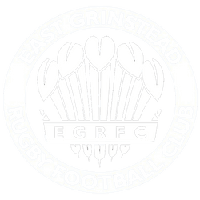

Saved 1600x900 match dashboard: /Users/samlindsay/Documents/Projects/Personal/EGRFC/egrfc-stats/reports/generated/in_game_stats/notebook/in_game_match_dashboard.html


In [13]:
import base64
import copy
from html import escape
from math import isfinite
from xml.etree import ElementTree

import vl_convert as vlc
from IPython.display import HTML

DASHBOARD_GAME_ID = '2026-10-17_1st_Horsham'
DASHBOARD_DATE = '17/10/2026'
DASHBOARD_TITLE = 'Horsham 33 - 60 East Grinstead'
DASHBOARD_TEAM_ORDER = ('Opposition', 'EG')

def dashboard_svg(spec: dict[str, Any]) -> str:
    """Render a self-contained responsive SVG from a dashboard chart copy."""
    spec.setdefault('config', {}).update({'background': 'transparent', 'font': 'PT Sans Narrow', 'view': {'stroke': None}})
    root = ElementTree.fromstring(vlc.vegalite_to_svg(spec))
    root.set('viewBox', f'0 0 {root.attrib["width"]} {root.attrib["height"]}')
    root.set('width', '100%')
    root.set('height', '100%')
    root.set('preserveAspectRatio', 'xMidYMin meet')
    ElementTree.register_namespace('', 'http://www.w3.org/2000/svg')
    return ElementTree.tostring(root, encoding='unicode')

def dashboard_chart_svg(chart: Any, compact: bool = False) -> str:
    """Fit unlabeled total/quarter chart copies to the dashboard columns."""
    spec = copy.deepcopy(chart.to_dict(validate=True))
    spec.pop('title', None)
    spec['bounds'] = 'flush'
    spec['spacing'] = 26 if compact else 30
    target_width = 420 if compact else 450
    for panel_index, panel in enumerate(spec['vconcat']):
        original_width = panel['width']
        panel['width'] = target_width
        panel['height'] = (28 if panel_index == 0 else 140) if compact else (30 if panel_index == 0 else 120)
        panel['layer'] = [layer for layer in panel['layer'] if layer.get('encoding', {}).get('text', {}).get('field') not in ('team_label', 'encoding_label')]
        for layer in panel['layer']:
            encoding = layer.get('encoding', {})
            x_encoding = encoding.get('x', {})
            if 'value' in x_encoding:
                x_encoding['value'] *= target_width / original_width
            for channel in ('x', 'y'):
                position = encoding.get(channel, {})
                if 'field' in position or 'datum' in position:
                    position['title'] = None
                if isinstance(position.get('axis'), dict):
                    position['axis']['title'] = None
            if isinstance(x_encoding.get('axis'), dict):
                x_encoding['axis'].update({'labelFontSize': 15, 'tickCount': 5})
            y_encoding = encoding.get('y', {})
            if isinstance(y_encoding.get('axis'), dict):
                y_encoding['axis']['labelFontSize'] = 17
            label_field = encoding.get('text', {}).get('field')
            if label_field == 'tackles':
                domain = panel['layer'][0]['encoding']['x']['scale']['domain']
                pixels_per_tackle = target_width / (domain[1] - domain[0])
                segment_width = f'datum.tackles * {pixels_per_tackle}'
                digit_count = "length(format(datum.tackles, '.0f'))"
                layer['mark'].pop('dy', None)
                layer['mark']['fontSize'] = {'expr': f'{segment_width} < {digit_count} * 10 + 6 ? 12 : 18'}
                layer['transform'] = [*layer.get('transform', []), {'filter': f'{segment_width} >= max(12, {digit_count} * 7 + 4)'}]
            elif label_field == 'outcome_label':
                layer['mark'].update({'fontSize': 18, 'baseline': 'bottom'})
                encoding['y'] = {'value': -8}
    return dashboard_svg(spec)

def dashboard_donut_svg(chart: Any, large: bool = False) -> str:
    """Render caption-free dashboard rings, with larger tackle charts."""
    spec = copy.deepcopy(chart.to_dict(validate=True))
    spec['width'], spec['height'] = (240, 224) if large else (224, 202)
    spec['padding'] = 0
    spec['autosize'] = 'none'
    for layer in spec['layer']:
        mark = layer['mark']
        if mark['type'] == 'arc':
            mark.update({'innerRadius': 43 if large else 36, 'outerRadius': 88 if large else 74})
        elif layer.get('encoding', {}).get('text', {}).get('field') in ('tackles', 'count', 'share_label'):
            mark.update({'radius': 66 if large else 55, 'fontSize': 20 if large else 17})
        elif layer.get('encoding', {}).get('text', {}).get('field') == 'outcome_label':
            mark.update({'radius': 106 if large else 91, 'fontSize': 18 if large else 17})
        elif layer.get('encoding', {}).get('text', {}).get('field') == 'completion':
            mark['fontSize'] = 38 if large else 34
    return dashboard_svg(spec)

def binary_donut(
    team: str, labels: tuple[str, str], counts: tuple[float, float],
    centre_text: str, slice_text: str = 'count', centre_caption: str = '',
) -> Any:
    """Normalize a two-outcome ring; the second outcome is white and dashed."""
    total = sum(counts)
    frame = pd.DataFrame({'team': team, 'outcome': list(labels), 'count': list(counts), 'order': [0, 1]})
    frame['share'] = frame['count'] / total if total else 0.0
    frame['share_label'] = frame['share'].map(lambda share: f'{share:.0%}')
    frame['segment_colour'] = [tackle_team_colours[team], '#ffffff']
    second = labels[1]
    base = alt.Chart(frame).encode(theta=alt.Theta('share:Q', stack=True), order=alt.Order('order:Q'))
    arcs = base.mark_arc(
        innerRadius=37, outerRadius=70,
        stroke=alt.ExprRef(expr=f"datum.outcome === '{second}' ? '#000000' : datum.segment_colour"),
        strokeWidth=alt.ExprRef(expr=f"datum.outcome === '{second}' ? 0.6 : 1"),
        strokeDash=alt.ExprRef(expr=f"datum.outcome === '{second}' ? [3, 2] : [1, 0]"),
    ).encode(color=alt.Color('segment_colour:N', scale=None, legend=None), tooltip=['team:N', 'outcome:N', alt.Tooltip('count:Q', format='.0f'), alt.Tooltip('share:Q', format='.1%')])
    slice_labels = base.transform_filter(alt.datum.count > 0).mark_text(radius=54, font='PT Sans Narrow', fontSize=17, fontWeight='bold').encode(
        text=alt.Text('count:Q', format='.0f') if slice_text == 'count' else alt.Text('share_label:N'),
        color=alt.condition(f"datum.outcome === '{second}'", alt.value('#111111'), alt.value('white')),
    )
    outcomes = base.transform_calculate(outcome_label="datum.count > 0 ? datum.outcome : ''").mark_text(radius=87, font='PT Sans Narrow', fontSize=17, fontWeight='bold', color='#111111').encode(text='outcome_label:N')
    centre_frame = pd.DataFrame({'completion': [centre_text], 'centre_caption': [centre_caption]})
    centre = alt.Chart(centre_frame).mark_text(font='PT Sans Narrow', fontSize=34, fontWeight='bold', color=tackle_team_colours[team], dy=-5 if centre_caption else 0).encode(text='completion:N')
    chart = arcs + slice_labels + outcomes + centre
    if centre_caption:
        chart += alt.Chart(centre_frame).mark_text(font='PT Sans Narrow', fontSize=17, color='#62646c', dy=19).encode(text='centre_caption:N')
    return chart

def validated_counts(values: dict[str, Any], label: str) -> tuple[float, ...]:
    """Reject missing, negative, fractional or non-finite source counts."""
    counts = tuple(float(value) if value is not None else float('nan') for value in values.values())
    if not all(isfinite(value) and value >= 0 and value.is_integer() for value in counts):
        raise ValueError(f'Invalid {label} counts: {values}')
    return counts

def dashboard_set_piece(metric: str, team_stats: dict[str, dict[str, Any]]) -> tuple[dict[str, Any], list[dict[str, Any]]]:
    """Build won/lost donuts from the website's canonical Google Sheets export."""
    prefix = {'Scrum': 'scrums', 'Lineout': 'lineouts'}[metric]
    charts, records = {}, []
    for team in DASHBOARD_TEAM_ORDER:
        row = team_stats[team]
        total, won = validated_counts({'total': row.get(f'{prefix}_total'), 'won': row.get(f'{prefix}_won')}, f'canonical {metric} {team}')
        if won > total:
            raise ValueError(f'Invalid canonical {metric} counts for {team}.')
        lost = total - won
        rate = won / total if total else None
        records.append({'team': team, 'total': total, 'won': won, 'lost': lost, 'success_rate': rate})
        charts[team] = binary_donut(team, ('Won', 'Lost'), (won, lost), f'{rate:.0%}' if rate is not None else '--')
    return charts, records

def dashboard_ruck_speed() -> tuple[dict[str, Any], list[dict[str, Any]]]:
    """Build <3 secs / 3+ secs donuts from full-match in-game ruck speed rows."""
    source = summary.loc[summary['section'].eq('Full Game') & summary['period'].eq('full_game') & summary['metric'].eq('Ruck Speed')]
    charts, records = {}, []
    for team in DASHBOARD_TEAM_ORDER:
        values = source.loc[source['team'].eq(team)].assign(outcome=lambda frame: frame['outcome'].fillna('Total'))
        if values['outcome'].duplicated().any() or not {'Total', '+', '-'}.issubset(values['outcome']):
            raise ValueError(f'Incomplete ruck speed outcomes for {team}.')
        counts = values.set_index('outcome')['count']
        total, quick, slow = validated_counts({key: counts[key] for key in ('Total', '+', '-')}, f'ruck speed {team}')
        if quick + slow != total:
            raise ValueError(f'Ruck speed outcomes do not sum to the total for {team}.')
        records.append({'team': team, 'total': total, 'under_3_secs': quick, 'over_3_secs': slow, 'under_3_secs_share': quick / total if total else None})
        charts[team] = binary_donut(team, ('<3 secs', '3+ secs'), (quick, slow), f'{total:.0f}', slice_text='share', centre_caption='rucks')
    return charts, records

def dashboard_donut_pair(charts: dict[str, Any], label: str, large: bool = False) -> str:
    """Keep accessible team names without redundant visible donut captions."""
    return '<div class="donut-pair">' + ''.join(
        f'<figure class="donut-figure" aria-label="{team} {escape(label)}">{dashboard_donut_svg(charts[team], large=large)}</figure>'
        for team in DASHBOARD_TEAM_ORDER
    ) + '</div>'

def dashboard_percentage_summary(frame: pd.DataFrame) -> dict[str, float]:
    """Return whole-match shares in consistent team order."""
    totals = frame.loc[frame['period_label'].eq('Total')].set_index('team')['share']
    if set(totals.index) != set(DASHBOARD_TEAM_ORDER):
        raise ValueError('Dashboard summaries require both teams for the full match.')
    return {team: float(totals[team]) for team in DASHBOARD_TEAM_ORDER}

def dashboard_share_html(shares: dict[str, float]) -> str:
    """Show whole-match percentages without a separate tall summary panel."""
    return (
        '<div class="share-summary">'
        f'<span class="opposition">Opposition <strong>{shares["Opposition"]:.0%}</strong></span>'
        f'<span class="eg"><strong>{shares["EG"]:.0%}</strong> EG</span></div>'
    )

canonical_games = json.loads((project_root / 'data/backend/games.json').read_text(encoding='utf-8'))
fixture_rows = [row for row in canonical_games if row.get('game_id') == DASHBOARD_GAME_ID]
if len(fixture_rows) != 1:
    raise ValueError('The dashboard requires a unique canonical match record.')
fixture = fixture_rows[0]
if (fixture.get('date'), fixture.get('squad'), fixture.get('score_for'), fixture.get('score_against')) != ('2026-10-17', '1st', 60, 33):
    raise ValueError('The canonical fixture does not match the requested dashboard title.')
canonical_set_piece = json.loads((project_root / 'data/backend/set_piece.json').read_text(encoding='utf-8'))
attacking_rows = [row for row in canonical_set_piece if row.get('game_id') == DASHBOARD_GAME_ID]
if len(attacking_rows) != 2 or {row.get('team') for row in attacking_rows} != {'EGRFC', 'Opposition'}:
    raise ValueError('Canonical set-piece summaries require exactly one record per team.')
attacking_stats = {('EG' if row['team'] == 'EGRFC' else 'Opposition'): row for row in attacking_rows}
territory_summary = dashboard_percentage_summary(territory_splits)
possession_summary = dashboard_percentage_summary(possession_splits)
whole_match_tackles = tackle_stats.xs('Total', level='period_label').reindex(DASHBOARD_TEAM_ORDER)
scrum_donut_charts, scrum_summary = dashboard_set_piece('Scrum', attacking_stats)
lineout_donut_charts, lineout_summary = dashboard_set_piece('Lineout', attacking_stats)
ruck_donut_charts, ruck_summary = dashboard_ruck_speed()
attacking_metrics = [('22m entries', 'entries_22m', '.0f'), ('Tries', 'tries', '.0f'), ('Try rate', 'tries_per_entry', '.0%'), ('Points / entry', 'points_per_entry', '.1f')]
attacking_html = ''.join(
    f'<tr><th scope="row">{label}</th>'
    + ''.join(f'<td class="{team.lower()}">{attacking_stats[team][field]:{number_format}}</td>' for team in DASHBOARD_TEAM_ORDER)
    + '</tr>' for label, field, number_format in attacking_metrics
)
primary, red = css_tokens['--primary-color'], css_tokens['--red-color']
competition_label = escape(str(fixture.get('competition', '')))
dashboard_logo = base64.b64encode((project_root / 'img/logos/EastGrinstead.png').read_bytes()).decode('ascii')
match_dashboard_payload = {
    'game_id': DASHBOARD_GAME_ID, 'title': DASHBOARD_TITLE, 'date': DASHBOARD_DATE,
    'team_order': list(DASHBOARD_TEAM_ORDER),
    'tackles': whole_match_tackles[['Made', 'Missed', 'tackle_percentage']].reset_index().to_dict(orient='records'),
    'ruck_speed': ruck_summary,
    'scrums': scrum_summary, 'lineouts': lineout_summary,
    'territory': territory_summary, 'possession': possession_summary,
    'ball_in_play_time': reported_ball_time.loc['Total', 'duration_text'],
    'attacking': {team: attacking_stats[team] for team in DASHBOARD_TEAM_ORDER},
    'sources': {'charts': stats['source'], 'ruck_speed': stats['source'], 'scrums': 'data/backend/set_piece.json', 'lineouts': 'data/backend/set_piece.json', 'attacking': 'data/backend/set_piece.json'},
}
match_dashboard_html = f'''<!DOCTYPE html>
<html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">
<title>{escape(DASHBOARD_TITLE)} | {DASHBOARD_DATE}</title>
<style>
:root {{ --primary: {primary}; --red: {red}; --paper: #f2f1f4; --ink: #242424; --rule: #aeb3bf; --column-rule: #7d8598; }}
* {{ box-sizing: border-box; }}
body {{ margin: 0; background: #d9dadd; color: var(--ink); font-family: 'PT Sans Narrow', 'Arial Narrow', sans-serif; letter-spacing: 0; }}
.dashboard {{ width: 1600px; height: 900px; padding: 22px 28px; display: grid; grid-template-rows: 116px minmax(0, 1fr); gap: 14px; background: var(--paper); }}
.match-header {{ display: flex; align-items: center; justify-content: space-between; background: var(--primary); color: white; padding: 8px 16px; gap: 24px; }}
.match-identity {{ display: flex; align-items: center; gap: 16px; min-width: 0; }}
.club-logo {{ width: 100px; height: 100px; object-fit: contain; flex: none; }}
h1 {{ font-size: 42px; line-height: 1.05; color: white; margin: 0 0 4px; font-weight: 700; }}
.match-header p {{ margin: 0; font-size: 22px; color: white; }}
.match-date {{ font-size: 26px; font-weight: 700; white-space: nowrap; color: white; }}
.dashboard-columns {{ display: grid; grid-template-columns: minmax(0, 1fr) minmax(0, 1.08fr) minmax(0, 1fr); gap: 22px; min-height: 0; }}
.dashboard-column {{ min-width: 0; min-height: 0; display: grid; gap: 14px; }}
.column-possession {{ grid-template-rows: repeat(2, minmax(0, 1fr)) 24px; }}
.column-tackles {{ grid-template-rows: minmax(0, 1fr) 256px; border-left: 2px solid var(--column-rule); border-right: 2px solid var(--column-rule); padding: 0 14px; }}
.column-set-piece {{ grid-template-rows: 228px 228px minmax(0, 1fr); }}
.dashboard-column > section {{ min-height: 0; }}
.analysis-section {{ min-width: 0; min-height: 0; display: grid; grid-template-rows: auto auto minmax(0, 1fr); gap: 4px; }}
h2 {{ font-size: 28px; line-height: 1; margin: 0; padding: 5px 8px 6px; color: var(--primary); background: #e1e4eb; border-left: 4px solid var(--primary); border-bottom: 1px solid var(--column-rule); }}
.tackles-section {{ grid-template-rows: auto 196px minmax(0, 1fr); gap: 6px; }}
.donut-section {{ display: grid; grid-template-rows: auto minmax(0, 1fr); min-height: 0; gap: 4px; }}
.donut-pair {{ display: grid; grid-template-columns: repeat(2, minmax(0, 1fr)); gap: 8px; min-height: 0; }}
.donut-figure {{ margin: 0; min-width: 0; min-height: 0; }}
.donut-figure svg {{ display: block; width: 100%; height: 100%; }}
.eg {{ color: var(--primary); }}
.opposition {{ color: var(--red); }}
.share-summary {{ display: flex; justify-content: space-between; align-items: baseline; gap: 12px; font-size: 21px; line-height: 1.15; padding: 2px 0; }}
.share-summary strong {{ font-size: 30px; padding: 0 4px; }}
.chart-panel {{ position: relative; min-height: 0; min-width: 0; overflow: hidden; margin: 0; }}
.chart-panel svg {{ position: absolute; inset: 0; display: block; width: 100%; height: 100%; }}
.attacking {{ min-height: 0; }}
.attacking h2 {{ margin-bottom: 6px; }}
.attacking table {{ border-collapse: collapse; width: 100%; font-size: 24px; }}
.attacking th, .attacking td {{ padding: 2px 8px; text-align: right; border-bottom: 1px solid var(--rule); }}
.attacking th:first-child {{ text-align: left; padding-left: 0; font-weight: 400; }}
.attacking thead th {{ font-size: 20px; }}
.attacking td {{ font-size: 28px; font-weight: 700; }}
.ball-in-play-note {{ margin: 0; padding-top: 4px; border-top: 1px solid var(--rule); font-size: 17px; line-height: 20px; color: #62646c; }}
@media (max-width: 1599px) {{ .dashboard {{ transform: scale(calc(100vw / 1600px)); transform-origin: top left; }} body {{ width: 100%; overflow-x: hidden; }} }}
@media print {{ @page {{ size: 16in 9in; margin: 0; }} body {{ background: white; }} .dashboard {{ transform: none; }} }}
</style></head><body><main class="dashboard" aria-label="Match analysis dashboard">
<header class="match-header"><div class="match-identity"><img class="club-logo" src="data:image/png;base64,{dashboard_logo}" alt="East Grinstead RFC crest" width="100" height="100"><div><h1>{escape(DASHBOARD_TITLE)}</h1><p>1st XV | {competition_label}</p></div></div><time class="match-date" datetime="2026-10-17">{DASHBOARD_DATE}</time></header>
<div class="dashboard-columns">
<div class="dashboard-column column-possession">
<section class="analysis-section" aria-label="Territory"><h2>Territory</h2>{dashboard_share_html(territory_summary)}<figure class="chart-panel">{dashboard_chart_svg(possession_variants[('territory', 'normalized')], compact=True)}</figure></section>
<section class="analysis-section" aria-label="Possession"><h2>Possession</h2>{dashboard_share_html(possession_summary)}<figure class="chart-panel">{dashboard_chart_svg(possession_variants[('possession', 'normalized')], compact=True)}</figure></section>
<p class="ball-in-play-note">Ball in play time: {reported_ball_time.loc['Total', 'duration_text']}</p>
</div>
<div class="dashboard-column column-tackles">
<section class="analysis-section tackles-section" aria-label="Tackles"><h2>Tackles</h2>{dashboard_donut_pair(tackle_donut_charts, 'tackle breakdown', large=True)}<figure class="chart-panel">{dashboard_chart_svg(tackle_combined_chart)}</figure></section>
<section class="donut-section" aria-label="Ruck speed"><h2>Ruck Speed</h2>{dashboard_donut_pair(ruck_donut_charts, 'ruck speed')}</section>
</div>
<div class="dashboard-column column-set-piece">
<section class="donut-section" aria-label="Scrums"><h2>Scrums</h2>{dashboard_donut_pair(scrum_donut_charts, 'scrums')}</section>
<section class="donut-section" aria-label="Lineouts"><h2>Lineouts</h2>{dashboard_donut_pair(lineout_donut_charts, 'lineouts')}</section>
<section class="attacking" aria-label="Match Detail attacking summaries"><h2>Attack</h2><table><thead><tr><th scope="col"></th><th scope="col" class="opposition">Opposition</th><th scope="col" class="eg">EG</th></tr></thead><tbody>{attacking_html}</tbody></table></section>
</div></div>
</main></body></html>'''
match_dashboard_directory = project_root / 'reports/generated/in_game_stats/notebook'
match_dashboard_directory.mkdir(parents=True, exist_ok=True)
match_dashboard_path = match_dashboard_directory / 'in_game_match_dashboard.html'
match_dashboard_path.write_text(match_dashboard_html, encoding='utf-8')
(match_dashboard_directory / 'in_game_match_dashboard.json').write_text(json.dumps(match_dashboard_payload, indent=2, default=str) + '\n', encoding='utf-8')
display(HTML(f'<iframe title="Match analysis dashboard" srcdoc="{escape(match_dashboard_html, quote=True)}" style="width:100%;aspect-ratio:16/9;border:0;"></iframe>'))
print('Saved 1600x900 match dashboard:', match_dashboard_path)